# VFN Dataset Audit & YOLO Preparation Pipeline

This notebook prepares a curated subset of the **VIPER-FoodNet (VFN)** dataset for multi-item food object detection with YOLO (dataset preparation only; no model training).

**Pipeline Overview:**
0. **Load & Verify VFN Metadata**: Parse `category_ids.txt`, `annotations.txt`, and official `training.txt` / `validation.txt` / `testing.txt` splits (with strict assertions on dataset counts).
1. **Box Size Audit & Class Selection**:
   - Audit bounding box area ratios across all 82 VFN classes and export `box_size_report.csv`.
   - Select 28 balanced main-dish and co-occurring side-dish classes (dinner & breakfast clusters) maximizing multi-class images in `val`/`test` (with manual override support in `CONFIG`).
   - Filter images strictly: keep an image only if **all** of its boxes belong to the selected classes.
2. **Cross-Split Duplicate Check**: Detect exact (MD5) and near-duplicate (pHash, Hamming distance <= 5) images across `train-val`, `train-test`, and `val-test`. Remove duplicates from **train only** and export `duplicate_report.csv`.
3. **YOLO Conversion**: Clip boxes to image bounds, drop invalid boxes (`<= 1px`), normalize to `[0, 1]`, remap class IDs `0..N-1` (`class_mapping.csv`), copy images (Windows-safe, no symlinks), and write `data.yaml`.
4. **Visual Check & Final Statistics**: Draw boxes on 40 random images read directly from the generated YOLO `.txt` labels, and export `dataset_stats.csv`.


In [2]:
import hashlib
import os
import random
import shutil
from collections import Counter, defaultdict
from pathlib import Path

import imagehash
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from PIL import Image
from tqdm.auto import tqdm

# ==============================================================================
# CONFIG
# ==============================================================================
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Resolve relative paths regardless of whether notebook is run from repo root or data_pipeline/
_CWD = Path(".")
if (_CWD / "vfn_1_0").exists():
    PROJECT_ROOT = _CWD
elif (_CWD / ".." / "vfn_1_0").exists():
    PROJECT_ROOT = Path("..")
else:
    raise FileNotFoundError("Could not locate 'vfn_1_0/' relative to current directory.")

VFN_DIR = PROJECT_ROOT / "vfn_1_0"
META_DIR = VFN_DIR / "Meta"
IMAGES_DIR = VFN_DIR / "Images"

OUTPUT_DIR = PROJECT_ROOT / "data_pipeline"
YOLO_DIR = PROJECT_ROOT / "yolo_dataset"

# Optional manual class override: provide VFN category IDs (e.g., [4, 5, 7, ...]).
# Leave empty [] to use the automatic meal-cluster & multi-class optimizer.
MANUAL_CLASS_IDS = []

TARGET_NUM_CLASSES = 28
MIN_TRAIN_IMAGES_PER_CLASS = 85
PHASH_HAMMING_THRESHOLD = 5
VISUAL_CHECK_COUNT = 40

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"PROJECT_ROOT: {PROJECT_ROOT}")
print(f"VFN_DIR:      {VFN_DIR}")
print(f"OUTPUT_DIR:   {OUTPUT_DIR}")
print(f"YOLO_DIR:     {YOLO_DIR}")


PROJECT_ROOT: ..
VFN_DIR:      ..\vfn_1_0
OUTPUT_DIR:   ..\data_pipeline
YOLO_DIR:     ..\yolo_dataset


## Step 0: Load VFN Metadata & Verify Dataset Integrity

We load `category_ids.txt`, the official split files (`training.txt`, `validation.txt`, `testing.txt`), and `annotations.txt` (`image.jpg x1 y1 x2 y2 category_id`). Because VFN stores multi-category images inside each matching category subfolder under `Images/`, we build a unique `filename -> relative_path` lookup and assert all official dataset counts (`22,423` boxes, `14,991` images: `10,463` train / `1,562` val / `2,966` test).


In [3]:
# 1. Load category mapping
cat_id_to_name = {}
with open(META_DIR / "category_ids.txt", "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        cid_str, cname = line.split(maxsplit=1)
        cat_id_to_name[int(cid_str)] = cname

assert len(cat_id_to_name) == 82, f"Expected 82 categories, got {len(cat_id_to_name)}"

# 2. Load official splits (preserve strictly, never re-split)
split_files = {
    "train": "training.txt",
    "val": "validation.txt",
    "test": "testing.txt",
}
splits = {}
img_to_split = {}
for split_name, fname in split_files.items():
    with open(META_DIR / fname, "r", encoding="utf-8") as f:
        imgs = [line.strip() for line in f if line.strip()]
    splits[split_name] = imgs
    for im in imgs:
        img_to_split[im] = split_name

assert len(splits["train"]) == 10463, f"Expected 10463 train images, got {len(splits['train'])}"
assert len(splits["val"]) == 1562, f"Expected 1562 val images, got {len(splits['val'])}"
assert len(splits["test"]) == 2966, f"Expected 2966 test images, got {len(splits['test'])}"
assert len(img_to_split) == 14991, f"Expected 14991 unique split images, got {len(img_to_split)}"

# 3. Index unique image paths under vfn_1_0/Images/
img_paths = {}
dup_folder_entries = 0
for root, _, files in os.walk(IMAGES_DIR):
    for fn in files:
        if fn in img_paths:
            dup_folder_entries += 1
        else:
            img_paths[fn] = Path(root) / fn

assert len(img_paths) == 14991, f"Expected 14991 unique image files, got {len(img_paths)}"

# 4. Load annotations.txt: image.jpg x1 y1 x2 y2 category_id
ann_records = []
with open(META_DIR / "annotations.txt", "r", encoding="utf-8") as f:
    for line in f:
        parts = line.strip().split()
        if not parts:
            continue
        im_name = parts[0]
        y1, x1, y2, x2 = map(float, parts[1:5])
        cid = int(parts[5])
        ann_records.append({
            "image": im_name,
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2,
            "category_id": cid,
            "category_name": cat_id_to_name[cid],
            "split": img_to_split[im_name],
        })

ann_df = pd.DataFrame(ann_records)
assert len(ann_df) == 22423, f"Expected 22423 boxes, got {len(ann_df)}"
assert ann_df["image"].nunique() == 14991, f"Expected 14991 annotated images, got {ann_df['image'].nunique()}"

print(f"Verified VFN dataset: {len(ann_df):,} boxes across {ann_df['image'].nunique():,} images.")
print(f"Splits -> train: {len(splits['train']):,}, val: {len(splits['val']):,}, test: {len(splits['test']):,}")
print(f"(Multi-category folder copies skipped during indexing: {dup_folder_entries:,})")


Verified VFN dataset: 22,423 boxes across 14,991 images.
Splits -> train: 10,463, val: 1,562, test: 2,966
(Multi-category folder copies skipped during indexing: 2,838)


## Step 1A: Box Size Audit (Before Class Selection)

We inspect the real `(width, height)` of all 14,991 images and compute each bounding box's width fraction, height fraction, and area ratio relative to the image. Classes with predominantly tiny boxes (`area < 1%` of the image) are flagged so we can avoid them during class selection. Results are saved to `box_size_report.csv`.


In [4]:
# Read real dimensions for all 14,991 images
img_sizes = {}
for im_name, path in tqdm(img_paths.items(), desc="Reading image dimensions"):
    with Image.open(path) as im:
        img_sizes[im_name] = im.size  # (width, height)

ann_df["img_w"] = ann_df["image"].map(lambda x: img_sizes[x][0])
ann_df["img_h"] = ann_df["image"].map(lambda x: img_sizes[x][1])

# Compute clipped box fractions relative to image dimensions
x1_c = np.clip(ann_df["x1"].values, 0.0, ann_df["img_w"].values)
y1_c = np.clip(ann_df["y1"].values, 0.0, ann_df["img_h"].values)
x2_c = np.clip(ann_df["x2"].values, 0.0, ann_df["img_w"].values)
y2_c = np.clip(ann_df["y2"].values, 0.0, ann_df["img_h"].values)

bw_c = np.maximum(0.0, x2_c - x1_c)
bh_c = np.maximum(0.0, y2_c - y1_c)

ann_df["w_frac"] = bw_c / ann_df["img_w"].values
ann_df["h_frac"] = bh_c / ann_df["img_h"].values
ann_df["area_ratio"] = ann_df["w_frac"] * ann_df["h_frac"]
ann_df["is_very_small"] = ann_df["area_ratio"] < 0.01

# Per-class image counts by split
split_img_counts = (
    ann_df.groupby(["category_id", "split"])["image"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=["train", "val", "test"], fill_value=0)
)

box_size_report = (
    ann_df.groupby(["category_id", "category_name"], as_index=False)
    .agg(
        total_boxes=("image", "count"),
        median_w_frac=("w_frac", "median"),
        median_h_frac=("h_frac", "median"),
        median_area_ratio=("area_ratio", "median"),
        very_small_boxes_lt_1pct=("is_very_small", "sum"),
    )
)
box_size_report["very_small_pct"] = (
    box_size_report["very_small_boxes_lt_1pct"] / box_size_report["total_boxes"] * 100.0
).round(2)

box_size_report = box_size_report.merge(
    split_img_counts.reset_index().rename(columns={"train": "train_imgs", "val": "val_imgs", "test": "test_imgs"}),
    on="category_id",
)
box_size_report = box_size_report.sort_values("category_id").reset_index(drop=True)

box_size_csv_path = OUTPUT_DIR / "box_size_report.csv"
box_size_report.to_csv(box_size_csv_path, index=False)
print(f"Saved {box_size_csv_path}")

print("\nTop 10 classes with highest % of very small boxes (<1% image area):")
display(box_size_report.sort_values("very_small_pct", ascending=False).head(10)[
    ["category_id", "category_name", "total_boxes", "median_area_ratio", "very_small_boxes_lt_1pct", "very_small_pct"]
])

inside = (ann_df["x2"] <= ann_df["img_w"] + 1) & (ann_df["y2"] <= ann_df["img_h"] + 1)
assert inside.mean() > 0.99, f"Only {inside.mean()*100:.1f}% of the boxes are inside the image: the coordinates are either being read on the wrong axis or the wrong size"
print(f"The box is inside the picture frame: {inside.mean()*100:.2f}%")


Reading image dimensions: 100%|██████████| 14991/14991 [00:07<00:00, 1947.03it/s]


Saved ..\data_pipeline\box_size_report.csv

Top 10 classes with highest % of very small boxes (<1% image area):


,category_id,category_name,total_boxes,median_area_ratio,very_small_boxes_lt_1pct,very_small_pct
13,13,blueberries,606,0.030796,147,24.26
0,0,almonds,211,0.059039,40,18.96
1,1,apple,613,0.117527,26,4.24
72,72,tomatoes,388,0.085484,14,3.61
69,69,strawberries,346,0.079858,11,3.18
22,22,cantaloupe,234,0.186103,6,2.56
23,23,carrot,193,0.203528,3,1.55
41,41,french_fries,260,0.343311,2,0.77
12,12,black_beans,139,0.219909,1,0.72
3,3,apple_sauce,171,0.337374,1,0.58


The box is inside the picture frame: 99.99%


## Step 1B: Class Selection & Strict Image Filtering

We select 28 classes (or use `MANUAL_CLASS_IDS` if provided in `CONFIG`) from main dishes and co-occurring side dishes across **Dinner/Lunch** and **Breakfast** meal clusters, avoiding:
- Fruits, desserts, drinks/beverages, and snacks skew.
- Classes that are hard or ambiguous to map to **USDA FoodData Central** calories (e.g., `soup`, `fruit_drink`, `milk`, `beer`, `red_wine`, `white_wine`, `chocolate_milk`, since mixed soups and varied drinks have high ingredient/kcal variance).
- Classes with predominantly tiny boxes (e.g., `almonds`, `blueberries`, `strawberries`, `tomatoes`, `apple`, `coleslaw`).
- Visually overlapping pastry/variant groups (`cake`/`cupcake`/`muffin`/`doughnut`, `brown_rice`, `chicken_nugget`, wines).

Under the **strict filtering rule**, an image is retained only if **every** bounding box in that image belongs to the selected classes.


In [5]:
# Build per-image box class list for fast filtering evaluation
img_box_cids = ann_df.groupby("image")["category_id"].apply(list).to_dict()

def evaluate_class_subset(selected_ids):
    sel_set = set(selected_ids)
    kept_by_split = {"train": [], "val": [], "test": []}
    mc_by_split = Counter()
    sc2_by_split = Counter()
    one_box_by_split = Counter()
    class_train_imgs = Counter()

    for im_name, cids in img_box_cids.items():
        if all(c in sel_set for c in cids):
            sp = img_to_split[im_name]
            kept_by_split[sp].append(im_name)
            distinct = set(cids)
            if len(cids) == 1:
                one_box_by_split[sp] += 1
            elif len(distinct) >= 2:
                mc_by_split[sp] += 1
            else:
                sc2_by_split[sp] += 1
            if sp == "train":
                for c in distinct:
                    class_train_imgs[c] += 1

    return kept_by_split, one_box_by_split, mc_by_split, sc2_by_split, class_train_imgs

# Meal-cluster metadata for candidate pool (Main Dishes + Co-occurring Sides)
MEAL_CLUSTER_ROLES = {
    # Dinner / Lunch Main Dishes
    "steak": "Dinner Main",
    "meat_loaf": "Dinner Main",
    "chicken_breast": "Dinner Main",
    "chicken_thigh": "Dinner Main",
    "chicken_tender": "Dinner Main",
    "pork_chop": "Dinner Main",
    "pizza": "Dinner Main",
    "pork_rib": "Dinner Main",
    "grilled_salmon": "Dinner Main",
    "shrimp": "Dinner Main",
    "pasta": "Lunch/Dinner Main",
    "pizza": "Lunch/Dinner Main",
    "cheese_burger": "Lunch/Dinner Main",
    "chicken_wing": "Lunch/Dinner Main",
    "hot_dog": "Lunch/Dinner Main",
    # Dinner / Lunch Side Dishes
    "mashed_potatoes": "Dinner Side",
    "baked_potato": "Dinner Side",
    "french_fries": "Dinner Side",
    "green_beans": "Dinner Side",
    "broccoli": "Dinner Side",
    "white_rice": "Dinner Side",
    "fried_rice": "Dinner Side",
    "carrot": "Dinner Side",
    "cabbage": "Dinner Side",
    "baked_beans": "Dinner Side",
    "avocado": "Meal Side",
    "chips": "Meal Side",
    # Breakfast Cluster (Mains + Sides)
    "fried_egg": "Breakfast Main",
    "pancake": "Breakfast Main",
    "waffle": "Breakfast Main",
    "hash_brown": "Breakfast Side",
    "bacon": "Breakfast Side",
    "yeast_bread": "Breakfast/Meal Side",
}

if MANUAL_CLASS_IDS:
    selected_class_ids = sorted(set(MANUAL_CLASS_IDS))
    selection_mode = "MANUAL OVERRIDE"
else:
    selection_mode = "AUTOMATIC MEAL-CLUSTER & MULTI-CLASS OPTIMIZATION"
    name_to_id = {v: k for k, v in cat_id_to_name.items()}
    pool_ids = [name_to_id[n] for n in MEAL_CLUSTER_ROLES if n in name_to_id]

    # Core meal-cluster anchors (dinner mains/sides + breakfast mains/sides; excludes soup/drinks for clean USDA mapping)
    core_names = [
        "steak", "meat_loaf", "chicken_breast", "chicken_thigh", "pork_chop", "pizza",
        "pasta", "cheese_burger", "shrimp",
        "mashed_potatoes", "baked_potato", "french_fries", "green_beans", "broccoli",
        "white_rice", "fried_rice", "carrot",
        "fried_egg", "hash_brown", "bacon", "pancake", "yeast_bread",
    ]
    selected_class_ids = [name_to_id[n] for n in core_names]
    remaining_pool = [cid for cid in pool_ids if cid not in selected_class_ids]

    # Greedily expand up to TARGET_NUM_CLASSES maximizing val+test multi-class images
    while len(selected_class_ids) < TARGET_NUM_CLASSES and remaining_pool:
        best_cid = None
        best_score = -1.0
        for cid in remaining_pool:
            cand = selected_class_ids + [cid]
            _, _, mc, _, ctr = evaluate_class_subset(cand)
            if ctr[cid] < MIN_TRAIN_IMAGES_PER_CLASS:
                continue
            score = mc["val"] + mc["test"] + 0.1 * mc["train"]
            if score > best_score:
                best_score = score
                best_cid = cid
        if best_cid is None:
            break
        selected_class_ids.append(best_cid)
        remaining_pool.remove(best_cid)

    selected_class_ids = sorted(selected_class_ids)

selected_set = set(selected_class_ids)
kept_by_split, one_box_cnt, mc_cnt, sc2_cnt, class_train_cnt = evaluate_class_subset(selected_class_ids)

print(f"Selection mode: {selection_mode} ({len(selected_class_ids)} classes)")
print("\nSelected Classes & Reasoning:")
reason_rows = []
bs_lookup = box_size_report.set_index("category_id")
for cid in selected_class_ids:
    cname = cat_id_to_name[cid]
    role = MEAL_CLUSTER_ROLES.get(cname, "Manual Selection")
    med_area = bs_lookup.loc[cid, "median_area_ratio"]
    small_pct = bs_lookup.loc[cid, "very_small_pct"]
    reason_rows.append({
        "vfn_id": cid,
        "class_name": cname,
        "cluster_role": role,
        "train_imgs_after_filter": class_train_cnt[cid],
        "median_area_ratio": round(float(med_area), 3),
        "small_box_pct": round(float(small_pct), 1),
    })

reason_df = pd.DataFrame(reason_rows)
display(reason_df)

# Print filtering summary table per split
filter_summary_rows = []
for sp in ["train", "val", "test"]:
    filter_summary_rows.append({
        "split": sp,
        "total_images": len(kept_by_split[sp]),
        "1_box": one_box_cnt[sp],
        "multi_class": mc_cnt[sp],
        "same_class_x2+": sc2_cnt[sp],
    })
filter_summary_df = pd.DataFrame(filter_summary_rows)
print("\nImages remaining after strict class filtering:")
display(filter_summary_df)


Selection mode: AUTOMATIC MEAL-CLUSTER & MULTI-CLASS OPTIMIZATION (28 classes)

Selected Classes & Reasoning:


,vfn_id,class_name,cluster_role,train_imgs_after_filter,median_area_ratio,small_box_pct
0,4,avocado,Meal Side,102,0.189,0.0
1,5,bacon,Breakfast Side,85,0.197,0.0
2,7,baked_beans,Dinner Side,111,0.505,0.0
3,8,baked_potato,Dinner Side,216,0.456,0.0
4,16,broccoli,Dinner Side,92,0.113,0.4
5,20,cabbage,Dinner Side,117,0.398,0.0
6,23,carrot,Dinner Side,83,0.204,1.6
7,24,cheese_burger,Lunch/Dinner Main,100,0.506,0.0
8,26,chicken_breast,Dinner Main,167,0.352,0.0
9,28,chicken_tender,Dinner Main,161,0.406,0.0



Images remaining after strict class filtering:


,split,total_images,1_box,multi_class,same_class_x2+
0,train,3654,2943,460,251
1,val,547,427,69,51
2,test,1016,807,133,76


## Step 2: Cross-Split Duplicate Check (MD5 + Perceptual Hash)

To prevent data leakage across splits, we compute both **MD5** and **64-bit perceptual hash (`imagehash.phash`)** for all filtered images, comparing `train-val`, `train-test`, and `val-test` pairs (flagging exact MD5 matches or Hamming distance `<= 5`).
- All detected pairs are logged in `duplicate_report.csv`.
- Duplicates are removed from **TRAIN only** — `val` and `test` are never modified.


In [6]:
filtered_images = {sp: list(kept_by_split[sp]) for sp in ["train", "val", "test"]}
all_filtered_names = filtered_images["train"] + filtered_images["val"] + filtered_images["test"]

md5_map = {}
phash_int_map = {}

for im_name in tqdm(all_filtered_names, desc="Hashing filtered images (MD5 + pHash)"):
    fpath = img_paths[im_name]
    with open(fpath, "rb") as f:
        md5_map[im_name] = hashlib.md5(f.read()).hexdigest()
    with Image.open(fpath) as im:
        ph = imagehash.phash(im.convert("RGB"))
        phash_int_map[im_name] = int(str(ph), 16)

def find_cross_split_duplicates(list_a, split_a, list_b, split_b, threshold=5):
    hashes_b = np.array([phash_int_map[x] for x in list_b], dtype=np.uint64)
    rows = []
    for im_a in tqdm(list_a, desc=f"Comparing {split_a} vs {split_b}"):
        ha = np.uint64(phash_int_map[im_a])
        md5_a = md5_map[im_a]
        # Fast vectorized Hamming distance on 64-bit hashes using byte lookup
        xor_vals = np.bitwise_xor(hashes_b, ha)
        # Convert uint64 array to (N, 8) uint8 bytes and sum bitcounts
        byte_view = xor_vals.view(np.uint8).reshape(-1, 8)
        dists = np.unpackbits(byte_view, axis=1).sum(axis=1)
        match_idxs = np.where(dists <= threshold)[0]
        for idx in match_idxs:
            im_b = list_b[int(idx)]
            rows.append({
                "pair_type": f"{split_a}-{split_b}",
                "img_a": im_a,
                "split_a": split_a,
                "img_b": im_b,
                "split_b": split_b,
                "md5_match": md5_a == md5_map[im_b],
                "hamming_dist": int(dists[idx]),
            })
    return rows

dup_rows = []
dup_rows.extend(find_cross_split_duplicates(filtered_images["train"], "train", filtered_images["val"], "val", PHASH_HAMMING_THRESHOLD))
dup_rows.extend(find_cross_split_duplicates(filtered_images["train"], "train", filtered_images["test"], "test", PHASH_HAMMING_THRESHOLD))
dup_rows.extend(find_cross_split_duplicates(filtered_images["val"], "val", filtered_images["test"], "test", PHASH_HAMMING_THRESHOLD))

dup_df = pd.DataFrame(dup_rows)
train_to_remove = set()
if not dup_df.empty:
    def _removed_info(row):
        if row["split_a"] == "train":
            return pd.Series([row["img_a"], "train"])
        return pd.Series(["NONE (val/test preserved)", "none"])
    dup_df[["removed_image", "removed_split"]] = dup_df.apply(_removed_info, axis=1)
    train_to_remove = set(dup_df.loc[dup_df["removed_split"] == "train", "removed_image"])
else:
    dup_df = pd.DataFrame(columns=["pair_type", "img_a", "split_a", "img_b", "split_b", "md5_match", "hamming_dist", "removed_image", "removed_split"])

dup_csv_path = OUTPUT_DIR / "duplicate_report.csv"
dup_df.to_csv(dup_csv_path, index=False)

clean_splits = {
    "train": [im for im in filtered_images["train"] if im not in train_to_remove],
    "val": list(filtered_images["val"]),
    "test": list(filtered_images["test"]),
}

print(f"Saved {dup_csv_path} ({len(dup_df)} pairs logged)")
if not dup_df.empty:
    print("Duplicate pairs by split pair:")
    print(dup_df["pair_type"].value_counts().to_string())
print(f"Removed {len(train_to_remove)} duplicate images from TRAIN only.")
print(f"Remaining -> train: {len(clean_splits['train']):,}, val: {len(clean_splits['val']):,}, test: {len(clean_splits['test']):,}")


Comparing val vs test: 100%|██████████| 547/547 [00:00<00:00, 15057.22it/s]

Saved ..\data_pipeline\duplicate_report.csv (96 pairs logged)
Duplicate pairs by split pair:
pair_type
train-test    53
train-val     32
val-test      11
Removed 78 duplicate images from TRAIN only.
Remaining -> train: 3,576, val: 547, test: 1,016


## Step 3: Convert to YOLO Format

We clear any previous `yolo_dataset/` output so the notebook can be re-run cleanly, remap the selected VFN class IDs to `0..N-1` (`class_mapping.csv`), clip boxes to image bounds, drop invalid boxes (`width <= 1px` or `height <= 1px`), normalize coordinates to `[0, 1]`, copy image files (Windows-safe, no symlinks), and write `data.yaml`.


In [7]:
# Clear old YOLO output for clean re-runs
if YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)

for sp in ["train", "val", "test"]:
    (YOLO_DIR / "images" / sp).mkdir(parents=True, exist_ok=True)
    (YOLO_DIR / "labels" / sp).mkdir(parents=True, exist_ok=True)

# Remap VFN class IDs -> 0..N-1
vfn_to_yolo = {vfn_id: idx for idx, vfn_id in enumerate(selected_class_ids)}
yolo_to_vfn = {idx: vfn_id for vfn_id, idx in vfn_to_yolo.items()}
yolo_names = [cat_id_to_name[yolo_to_vfn[i]] for i in range(len(selected_class_ids))]

class_mapping_df = pd.DataFrame([
    {"yolo_id": i, "vfn_id": yolo_to_vfn[i], "class_name": yolo_names[i]}
    for i in range(len(selected_class_ids))
])
class_mapping_path = OUTPUT_DIR / "class_mapping.csv"
class_mapping_df.to_csv(class_mapping_path, index=False)

# Group annotations by image for fast lookup
img_ann_groups = {im: grp for im, grp in ann_df[ann_df["image"].isin(
    set(clean_splits["train"]) | set(clean_splits["val"]) | set(clean_splits["test"])
)].groupby("image")}

dropped_invalid_boxes = 0
dropped_empty_images = 0
kept_boxes_total = 0

for sp in ["train", "val", "test"]:
    for im_name in tqdm(clean_splits[sp], desc=f"Writing YOLO {sp}"):
        src_img = img_paths[im_name]
        w, h = img_sizes[im_name]
        grp = img_ann_groups[im_name]

        yolo_lines = []
        for _, row in grp.iterrows():
            x1 = max(0.0, min(float(row["x1"]), float(w)))
            y1 = max(0.0, min(float(row["y1"]), float(h)))
            x2 = max(0.0, min(float(row["x2"]), float(w)))
            y2 = max(0.0, min(float(row["y2"]), float(h)))

            bw = x2 - x1
            bh = y2 - y1
            if bw <= 1.0 or bh <= 1.0:
                dropped_invalid_boxes += 1
                continue

            xc = ((x1 + x2) / 2.0) / w
            yc = ((y1 + y2) / 2.0) / h
            wn = bw / w
            hn = bh / h
            yolo_cid = vfn_to_yolo[int(row["category_id"])]
            yolo_lines.append(f"{yolo_cid} {xc:.6f} {yc:.6f} {wn:.6f} {hn:.6f}")

        if not yolo_lines:
            dropped_empty_images += 1
            continue

        kept_boxes_total += len(yolo_lines)
        dst_img = YOLO_DIR / "images" / sp / im_name
        dst_lbl = YOLO_DIR / "labels" / sp / f"{Path(im_name).stem}.txt"
        shutil.copy2(src_img, dst_img)
        with open(dst_lbl, "w", encoding="utf-8") as f:
            f.write("\n".join(yolo_lines) + "\n")

# Write data.yaml using relative paths
data_yaml = {
    "path": ".",
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(yolo_names),
    "names": {i: name for i, name in enumerate(yolo_names)},
}
data_yaml_path = YOLO_DIR / "data.yaml"
with open(data_yaml_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False, allow_unicode=True)

print(f"Saved {class_mapping_path}")
print(f"Saved {data_yaml_path}")
print(f"Total boxes written: {kept_boxes_total:,} | Dropped invalid boxes (<=1px): {dropped_invalid_boxes} | Dropped empty images: {dropped_empty_images}")


Writing YOLO test: 100%|██████████| 1016/1016 [00:01<00:00, 560.21it/s]

Saved ..\data_pipeline\class_mapping.csv
Saved ..\yolo_dataset\data.yaml
Total boxes written: 6,860 | Dropped invalid boxes (<=1px): 0 | Dropped empty images: 0


## Step 4: Visual Check (From Generated YOLO Labels) & Dataset Statistics

We sample 40 random images across the generated YOLO dataset, read bounding boxes **strictly from the generated YOLO `.txt` label files** (never from `annotations.txt`), and render them for visual verification (`visual_check_grid.png`). Finally, we compute and export `dataset_stats.csv` directly from the generated YOLO dataset.


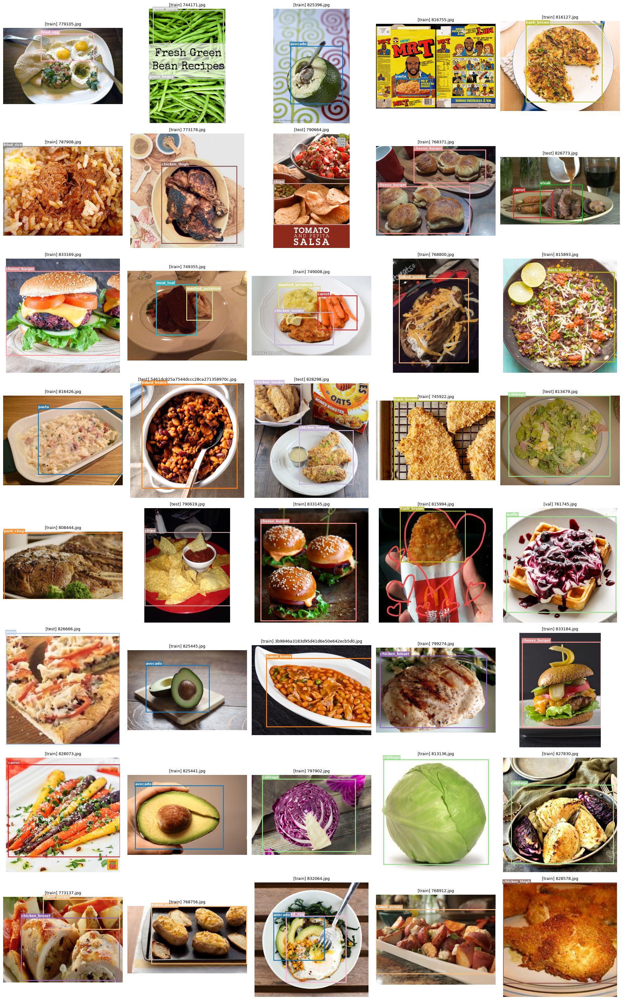

Saved ..\data_pipeline\visual_check_grid.png
Saved ..\data_pipeline\dataset_stats.csv

Final YOLO Dataset Split Summary:


,split,images,boxes,boxes_1,boxes_2,boxes_3,boxes_ge4,multi_class_images,same_class_x2plus_images
0,train,3576,4743,2883.0,435.0,165.0,93.0,451.0,242.0
29,val,547,749,427.0,74.0,28.0,18.0,69.0,51.0
58,test,1016,1368,807.0,131.0,50.0,28.0,133.0,76.0


In [8]:
# 1. Visual check on ~40 random images reading ONLY from generated YOLO labels
with open(YOLO_DIR / "data.yaml", "r", encoding="utf-8") as f:
    loaded_yaml = yaml.safe_load(f)
names_map = loaded_yaml["names"]

all_yolo_samples = []
for sp in ["train", "val", "test"]:
    for img_p in sorted((YOLO_DIR / "images" / sp).glob("*.jpg")):
        lbl_p = YOLO_DIR / "labels" / sp / f"{img_p.stem}.txt"
        all_yolo_samples.append((sp, img_p, lbl_p))

rng = random.Random(SEED)
vis_samples = rng.sample(all_yolo_samples, min(VISUAL_CHECK_COUNT, len(all_yolo_samples)))

ncols = 5
nrows = (len(vis_samples) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 4 * nrows))
axes = np.array(axes).reshape(-1)
palette = plt.cm.tab20(np.linspace(0, 1, 20))

for ax, (sp, img_p, lbl_p) in zip(axes, vis_samples):
    with Image.open(img_p) as im:
        im_rgb = im.convert("RGB")
        w, h = im_rgb.size
        ax.imshow(im_rgb)

    with open(lbl_p, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if not parts:
                continue
            cid = int(parts[0])
            xc, yc, wn, hn = map(float, parts[1:5])
            bw = wn * w
            bh = hn * h
            x1 = (xc * w) - bw / 2.0
            y1 = (yc * h) - bh / 2.0
            color = palette[cid % 20]
            rect = patches.Rectangle((x1, y1), bw, bh, linewidth=2, edgecolor=color, facecolor="none")
            ax.add_patch(rect)
            ax.text(
                x1, max(0, y1 - 4), names_map[cid],
                color="white", fontsize=8, fontweight="bold",
                bbox=dict(facecolor=color, alpha=0.8, pad=1.5, edgecolor="none"),
            )
    ax.set_title(f"[{sp}] {img_p.name}", fontsize=9)
    ax.axis("off")

for ax in axes[len(vis_samples):]:
    ax.axis("off")

plt.tight_layout()
vis_grid_path = OUTPUT_DIR / "visual_check_grid.png"
plt.savefig(vis_grid_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Saved {vis_grid_path}")

# 2. Export dataset_stats.csv directly from generated YOLO labels
stats_rows = []
for sp in ["train", "val", "test"]:
    lbl_files = sorted((YOLO_DIR / "labels" / sp).glob("*.txt"))
    n_imgs = len(lbl_files)
    n_boxes = 0
    b1 = b2 = b3 = b4p = 0
    mc_imgs = 0
    sc2_imgs = 0
    cls_img_cnt = Counter()
    cls_box_cnt = Counter()

    for lbl_p in lbl_files:
        cids = []
        with open(lbl_p, "r", encoding="utf-8") as f:
            for line in f:
                if line.strip():
                    cids.append(int(line.strip().split()[0]))
        k = len(cids)
        n_boxes += k
        if k == 1:
            b1 += 1
        elif k == 2:
            b2 += 1
        elif k == 3:
            b3 += 1
        elif k >= 4:
            b4p += 1

        distinct = set(cids)
        if len(distinct) >= 2:
            mc_imgs += 1
        elif k >= 2:
            sc2_imgs += 1

        for c in distinct:
            cls_img_cnt[c] += 1
        for c in cids:
            cls_box_cnt[c] += 1

    stats_rows.append({
        "section": "split_summary",
        "split": sp,
        "yolo_id": -1,
        "class_name": "ALL",
        "images": n_imgs,
        "boxes": n_boxes,
        "boxes_1": b1,
        "boxes_2": b2,
        "boxes_3": b3,
        "boxes_ge4": b4p,
        "multi_class_images": mc_imgs,
        "same_class_x2plus_images": sc2_imgs,
    })

    for cid in range(len(names_map)):
        stats_rows.append({
            "section": "class_breakdown",
            "split": sp,
            "yolo_id": cid,
            "class_name": names_map[cid],
            "images": cls_img_cnt[cid],
            "boxes": cls_box_cnt[cid],
            "boxes_1": np.nan,
            "boxes_2": np.nan,
            "boxes_3": np.nan,
            "boxes_ge4": np.nan,
            "multi_class_images": np.nan,
            "same_class_x2plus_images": np.nan,
        })

stats_df = pd.DataFrame(stats_rows)
stats_csv_path = OUTPUT_DIR / "dataset_stats.csv"
stats_df.to_csv(stats_csv_path, index=False)
print(f"Saved {stats_csv_path}")

print("\nFinal YOLO Dataset Split Summary:")
display(stats_df[stats_df["section"] == "split_summary"].drop(columns=["section", "yolo_id", "class_name"]))
